# Thí nghiệm 4: So sánh các biến thể cải tiến của GA

**Mục tiêu:** Đánh giá Nearest Neighbor Initialization, Adaptive Mutation và 2-opt Local Search trên các dataset thử nghiệm riêng.

---

## 1. Thiết lập môi trường

**Chế độ chạy:**
- `QUICK`: 5 seed [11, 23, 37, 53, 71]
- `FULL`: 25 seed [101-125]

**Cách chạy:** Restart Kernel & Run All

In [1]:
from pathlib import Path
from dataclasses import replace
from collections import Counter
from math import fsum, isclose
import platform
import statistics
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython import get_ipython
from IPython.display import display, Markdown

from ga_eho_tsp import __version__
from ga_eho_tsp.algorithms.ga import solve
from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import GAConfig
from ga_eho_tsp.domain.objective import validate_route

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 95, 'font.size': 10})

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'pyproject.toml').is_file() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở notebook từ root dự án hoặc Experiment/ sau khi cài package.')

MODE = 'QUICK'
SEEDS = [11, 23, 37, 53, 71] if MODE == 'QUICK' else list(range(101, 126))
MAX_RUNS = 200 if MODE == 'QUICK' else 1000
TOTAL_SOLVER_LIMIT = 180.0 if MODE == 'QUICK' else 900.0
RUN_COUNT, SOLVER_SECONDS = 0, 0.0

print(f'Python {platform.python_version()} | GA {__version__} | Chế độ {MODE}')
print(f'Seeds: {len(SEEDS)} | Max runs: {MAX_RUNS} | Time limit: {TOTAL_SOLVER_LIMIT}s')

Python 3.11.9 | GA 0.2.0 | Chế độ QUICK
Seeds: 5 | Max runs: 200 | Time limit: 180.0s


## 2. Hàm hỗ trợ

In [2]:
def show_table(headers, rows):
    """Hiển thị bảng kết quả"""
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))

def checked_solve(problem, config):
    """Chạy GA và kiểm tra tính hợp lệ"""
    global RUN_COUNT, SOLVER_SECONDS
    if RUN_COUNT >= MAX_RUNS or SOLVER_SECONDS >= TOTAL_SOLVER_LIMIT:
        raise RuntimeError('Vượt giới hạn notebook.')
    
    result = solve(problem, config)
    RUN_COUNT += 1
    SOLVER_SECONDS += result.elapsed_seconds
    
    validate_route(result.best_route, problem.dimension)
    route = result.best_route
    cost = fsum(problem.distance_matrix[route[i]][route[(i + 1) % len(route)]]
                for i in range(len(route)))
    assert result.is_valid and isclose(cost, result.best_distance, abs_tol=1e-9, rel_tol=1e-12)
    return result

def summarize(runs):
    """Tính toán các chỉ số thống kê"""
    distances = [r.best_distance for r in runs]
    return dict(
        mean=statistics.mean(distances),
        std=statistics.stdev(distances),
        best=min(distances),
        worst=max(distances),
        median=statistics.median(distances),
        seconds=statistics.mean(r.elapsed_seconds for r in runs),
        eval_mean=statistics.mean(r.evaluations for r in runs),
        reasons=dict(Counter(r.stopping_reason for r in runs))
    )

def compare_convergence(runs_dict, title, problem_name):
    """Vẽ đường hội tụ so sánh"""
    fig, ax = plt.subplots(figsize=(10, 6))
    
    colors = {'Baseline': '#1f77b4', 'NN Init': '#ff7f0e', 'Mixed': '#2ca02c', 
              'Adaptive': '#d62728', '2-opt': '#9467bd'}
    
    for label, runs in runs_dict.items():
        # Lấy run đại diện (seed đầu tiên)
        run = runs[0]
        evals = [h.evaluations for h in run.history]
        best_so_far = [h.best_so_far for h in run.history]
        ax.plot(evals, best_so_far, label=label, linewidth=2, color=colors.get(label, 'gray'))
    
    ax.set(xlabel='Số evaluations', ylabel='Độ dài tour tốt nhất', 
           title=f'{title} - {problem_name}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 3. Cấu hình baseline

**Tham số baseline (GA cơ bản):**

In [3]:
BASE = GAConfig(
    population_size=40,
    mutation_rate=0.15,
    generations=200,
    max_iterations=200,
    max_evaluations=8000,
    time_limit_seconds=30.0,
    local_search_enabled=False,
    initialization_method='random',
    adaptive_mutation=False
)

show_table(
    ['Tham số', 'Giá trị'],
    [
        ['Quần thể', BASE.population_size],
        ['Tỷ lệ đột biến', BASE.mutation_rate],
        ['Số thế hệ', BASE.generations],
        ['Max evaluations', BASE.max_evaluations],
        ['Local search', 'Tắt'],
        ['NN Init', 'Tắt'],
        ['Adaptive mutation', 'Tắt']
    ]
)

| Tham số | Giá trị |
| --- | --- |
| Quần thể | 40 |
| Tỷ lệ đột biến | 0.15 |
| Số thế hệ | 200 |
| Max evaluations | 8000 |
| Local search | Tắt |
| NN Init | Tắt |
| Adaptive mutation | Tắt |

---

## 4. Thí nghiệm 1: Baseline vs NN Initialization

### 4.1. Mục tiêu
So sánh GA cơ bản với GA sử dụng Nearest Neighbor Initialization.

### 4.2. Bài toán test
Dataset: `26Cities-937.txt` (26 thành phố)

### 4.3. Tham số
- **Baseline:** Random initialization
- **NN Init:** `initialization_method='nearest_neighbor'`, một số cá thể được khởi tạo bằng thuật toán Nearest Neighbor

### 4.4. Kết quả

| Biến thể | Tốt nhất | Trung bình | Trung vị | Kém nhất | Độ lệch chuẩn | Thời gian (s) |
| --- | --- | --- | --- | --- | --- | --- |
| Baseline | 962.00 | 992.40 | 998.00 | 1005.00 | 17.42 | 0.1041 |
| NN Init | 961.00 | 961.00 | 961.00 | 961.00 | 0.00 | 0.1036 |


✓ NN Init cải thiện: 3.16%


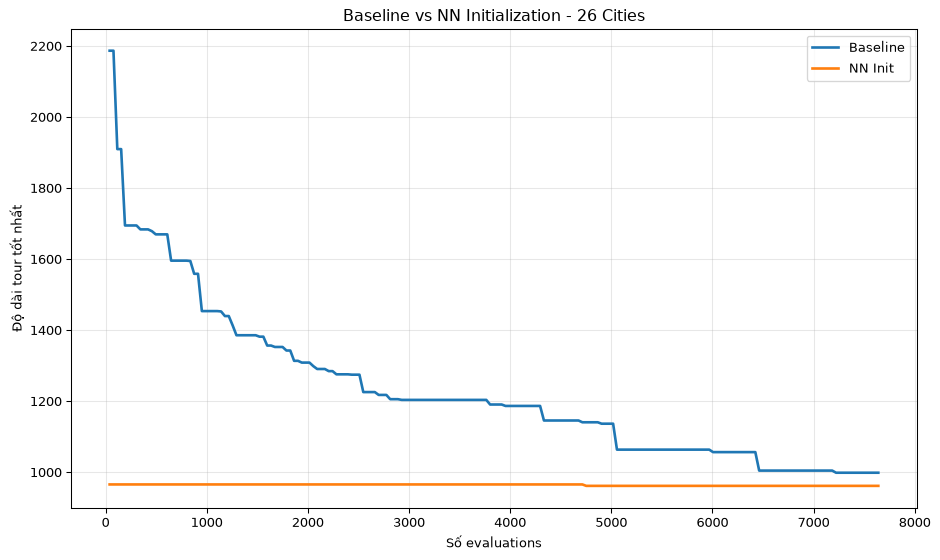

In [4]:
# Load dataset
problem_26 = load_matrix(ROOT / 'data' / '26Cities-937.txt')

# Baseline
runs_baseline = [checked_solve(problem_26, replace(BASE, seed=s)) for s in SEEDS]
stats_baseline = summarize(runs_baseline)

# NN Initialization
config_nn = replace(BASE, initialization_method='nearest_neighbor')
runs_nn = [checked_solve(problem_26, replace(config_nn, seed=s)) for s in SEEDS]
stats_nn = summarize(runs_nn)

# So sánh
show_table(
    ['Biến thể', 'Tốt nhất', 'Trung bình', 'Trung vị', 'Kém nhất', 'Độ lệch chuẩn', 'Thời gian (s)'],
    [
        ['Baseline', f"{stats_baseline['best']:.2f}", f"{stats_baseline['mean']:.2f}", 
         f"{stats_baseline['median']:.2f}", 
             f"{stats_baseline['worst']:.2f}", 
         f"{stats_baseline['std']:.2f}", f"{stats_baseline['seconds']:.4f}"],
        ['NN Init', f"{stats_nn['best']:.2f}", f"{stats_nn['mean']:.2f}", 
         f"{stats_nn['median']:.2f}", 
             f"{stats_nn['worst']:.2f}", 
         f"{stats_nn['std']:.2f}", f"{stats_nn['seconds']:.4f}"]
    ]
)

# Tính % cải thiện
improvement = ((stats_baseline['mean'] - stats_nn['mean']) / stats_baseline['mean']) * 100
print(f"\n✓ NN Init cải thiện: {improvement:.2f}%")

# Vẽ đường hội tụ
compare_convergence(
    {'Baseline': runs_baseline, 'NN Init': runs_nn},
    'Baseline vs NN Initialization',
    '26 Cities'
)

### 4.5. Nhận xét

Trong năm seed của dataset 26 thành phố, NN initialization cho mean distance 961,00, thấp hơn baseline 992,40; độ lệch chuẩn mẫu giảm từ 17,42 xuống 0. Đây là quan sát trên cấu hình và dataset này, không đảm bảo cải thiện trên dataset khác.


---

## 5. Thí nghiệm 2: Tournament selection trên dataset 42 thành phố

### Mục tiêu
Ghi nhận kết quả của cấu hình Tournament trên dataset `42Cities-699.txt` qua năm seed cố định. Bảng này mô tả cấu hình đã chạy, không phải so sánh giữa nhiều selection operator.

### Tham số
Dùng cấu hình GA baseline của notebook: population 40, Tournament `k=3`, OX, inversion, mutation rate 0,15, tối đa 8.000 evaluations/run.

### Kết quả


In [5]:
# Ghi nhận Tournament baseline trên dataset 42 thành phố.
problem_42 = load_matrix(ROOT / 'data' / '42Cities-699.txt')
runs_tournament = [checked_solve(problem_42, replace(BASE, seed=s)) for s in SEEDS]
stats_tournament = summarize(runs_tournament)

show_table(
    ['Biến thể', 'Tốt nhất', 'Trung bình', 'Trung vị', 'Kém nhất', 'Độ lệch chuẩn', 'Thời gian (s)'],
    [[
        'Tournament', f"{stats_tournament['best']:.2f}", f"{stats_tournament['mean']:.2f}",
        f"{stats_tournament['median']:.2f}", f"{stats_tournament['worst']:.2f}",
        f"{stats_tournament['std']:.2f}", f"{stats_tournament['seconds']:.4f}"
    ]]
)


| Biến thể | Tốt nhất | Trung bình | Trung vị | Kém nhất | Độ lệch chuẩn | Thời gian (s) |
| --- | --- | --- | --- | --- | --- | --- |
| Tournament | 876.00 | 906.60 | 888.00 | 985.00 | 44.59 | 0.1283 |

### Nhận xét

Bảng cho biết phân bố kết quả của Tournament trên năm seed. Các số liệu này dùng làm mô tả baseline cho dataset 42 thành phố, không đại diện cho một phép so sánh operator.


---

## 6. Thí nghiệm 3: Fixed vs Adaptive Mutation

### 6.1. Mục tiêu
So sánh Mutation cố định với Adaptive Mutation (tỷ lệ thay đổi theo tiến trình).

### 6.2. Bài toán test
Dataset: `48Cities-33523.txt` (48 thành phố)

### 6.3. Tham số
- **Fixed:** `mutation_rate=0.15` cố định
- **Adaptive:** `adaptive_mutation=True`, tỷ lệ giảm dần theo thế hệ

### 6.4. Kết quả

| Biến thể | Tốt nhất | Trung bình | Trung vị | Kém nhất | Độ lệch chuẩn | Thời gian (s) |
| --- | --- | --- | --- | --- | --- | --- |
| Fixed 0.15 | 40302.00 | 43279.00 | 44600.00 | 46230.00 | 2652.47 | 0.1404 |
| Adaptive | 41180.00 | 42709.80 | 42458.00 | 43949.00 | 1155.87 | 0.1414 |


Adaptive Mutation thay đổi mean distance: 1.32% so với baseline


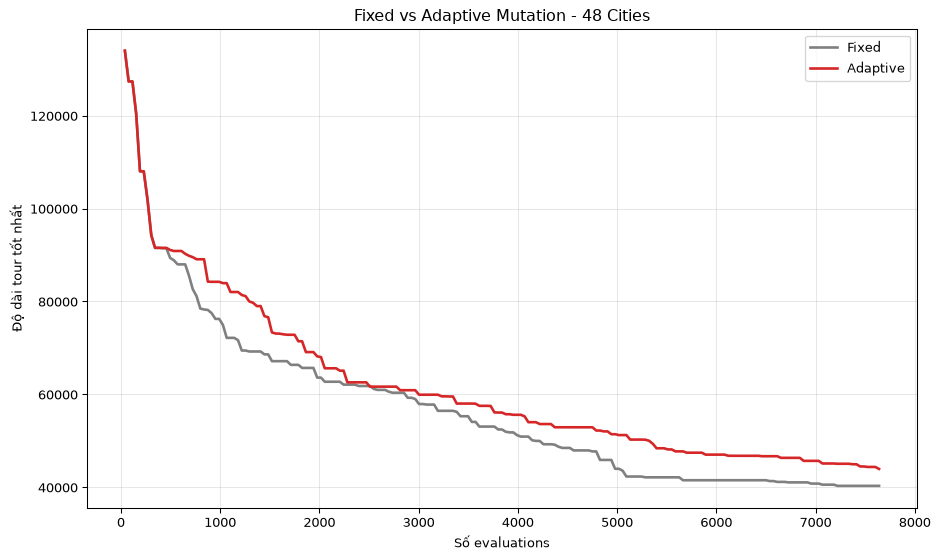

In [6]:
# Load dataset
problem_48 = load_matrix(ROOT / 'data' / '48Cities-33523.txt')

# Fixed mutation (baseline)
runs_fixed = [checked_solve(problem_48, replace(BASE, seed=s)) for s in SEEDS]
stats_fixed = summarize(runs_fixed)

# Adaptive mutation
config_adaptive = replace(BASE, adaptive_mutation=True)
runs_adaptive = [checked_solve(problem_48, replace(config_adaptive, seed=s)) for s in SEEDS]
stats_adaptive = summarize(runs_adaptive)

# So sánh
show_table(
    ['Biến thể', 'Tốt nhất', 'Trung bình', 'Trung vị', 'Kém nhất', 'Độ lệch chuẩn', 'Thời gian (s)'],
    [
        ['Fixed 0.15', f"{stats_fixed['best']:.2f}", f"{stats_fixed['mean']:.2f}", 
         f"{stats_fixed['median']:.2f}", 
             f"{stats_fixed['worst']:.2f}", 
         f"{stats_fixed['std']:.2f}", f"{stats_fixed['seconds']:.4f}"],
        ['Adaptive', f"{stats_adaptive['best']:.2f}", f"{stats_adaptive['mean']:.2f}", 
         f"{stats_adaptive['median']:.2f}", 
             f"{stats_adaptive['worst']:.2f}", 
         f"{stats_adaptive['std']:.2f}", f"{stats_adaptive['seconds']:.4f}"]
    ]
)

improvement = ((stats_fixed['mean'] - stats_adaptive['mean']) / stats_fixed['mean']) * 100
print(f"\nAdaptive Mutation thay đổi mean distance: {improvement:.2f}% so với baseline")

compare_convergence(
    {'Fixed': runs_fixed, 'Adaptive': runs_adaptive},
    'Fixed vs Adaptive Mutation',
    '48 Cities'
)

### 6.5. Nhận xét

Trên dataset 48 thành phố và năm seed, adaptive mutation có mean 42.709,80 so với 43.279,00 của mutation cố định, tức mean thấp hơn 1,32%; median và độ lệch chuẩn mẫu cũng thấp hơn. Tuy vậy, best observed của adaptive là 41.180, cao hơn 40.302 của baseline. Vì số run nhỏ và best không đồng chiều với mean, không thể kết luận adaptive tốt hơn ở mọi lần chạy.


---

## 7. Thí nghiệm 4: Impact of 2-opt Local Search

### 7.1. Mục tiêu
Đánh giá tác động của 2-opt Local Search lên chất lượng nghiệm.

### 7.2. Bài toán test
Dataset: `48Cities-33523.txt` (48 thành phố)

### 7.3. Tham số
- **No 2-opt:** `local_search_enabled=False`
- **With 2-opt:** `local_search_enabled=True`

### 7.4. Kết quả

| Biến thể | Tốt nhất | Trung bình | Trung vị | Kém nhất | Độ lệch chuẩn | Thời gian (s) | Evals TB |
| --- | --- | --- | --- | --- | --- | --- | --- |
| No 2-opt | 40302.00 | 43279.00 | 44600.00 | 46230.00 | 2652.47 | 0.1404 | 7640 |
| With 2-opt | 82513.00 | 90549.20 | 91742.00 | 99086.00 | 7079.05 | 0.0798 | 8000 |


2-opt: mean distance tăng 109.22% so với baseline
2-opt: runtime giảm 43.21% so với baseline


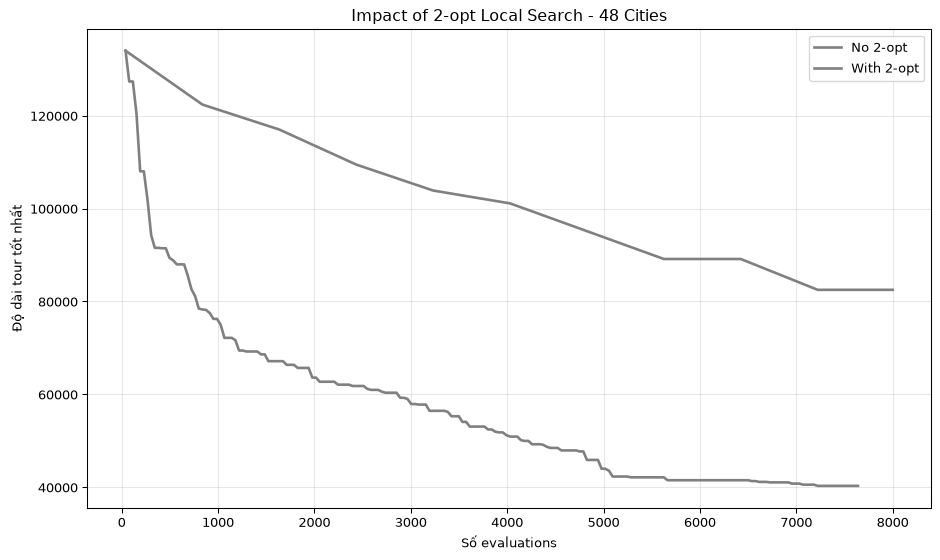

In [7]:
# No local search (already computed above as runs_fixed)
stats_no_ls = stats_fixed

# With 2-opt local search
config_2opt = replace(BASE, local_search_enabled=True, local_search_max_moves=50)
runs_2opt = [checked_solve(problem_48, replace(config_2opt, seed=s)) for s in SEEDS]
stats_2opt = summarize(runs_2opt)

# So sánh
show_table(
    ['Biến thể', 'Tốt nhất', 'Trung bình', 'Trung vị', 'Kém nhất', 'Độ lệch chuẩn', 'Thời gian (s)', 'Evals TB'],
    [
        ['No 2-opt', f"{stats_no_ls['best']:.2f}", f"{stats_no_ls['mean']:.2f}", 
         f"{stats_no_ls['median']:.2f}", 
             f"{stats_no_ls['worst']:.2f}", 
         f"{stats_no_ls['std']:.2f}", f"{stats_no_ls['seconds']:.4f}", 
         f"{stats_no_ls['eval_mean']:.0f}"],
        ['With 2-opt', f"{stats_2opt['best']:.2f}", f"{stats_2opt['mean']:.2f}", 
         f"{stats_2opt['median']:.2f}", 
             f"{stats_2opt['worst']:.2f}", 
         f"{stats_2opt['std']:.2f}", f"{stats_2opt['seconds']:.4f}",
         f"{stats_2opt['eval_mean']:.0f}"]
    ]
)

improvement = ((stats_no_ls['mean'] - stats_2opt['mean']) / stats_no_ls['mean']) * 100
time_overhead = ((stats_2opt['seconds'] - stats_no_ls['seconds']) / stats_no_ls['seconds']) * 100
if improvement > 0:
    quality_message = f"mean distance giảm {improvement:.2f}%"
else:
    quality_message = f"mean distance tăng {abs(improvement):.2f}%"
if time_overhead > 0:
    time_message = f"runtime tăng {time_overhead:.2f}%"
else:
    time_message = f"runtime giảm {abs(time_overhead):.2f}%"
print(f"\n2-opt: {quality_message} so với baseline")
print(f"2-opt: {time_message} so với baseline")

compare_convergence(
    {'No 2-opt': runs_fixed, 'With 2-opt': runs_2opt},
    'Impact of 2-opt Local Search',
    '48 Cities'
)

### 7.5. Nhận xét

Trong batch này, bật 2-opt làm mean distance tăng 109,22% so với baseline trên dataset 48 thành phố; độ lệch chuẩn mẫu cũng lớn hơn. Runtime trung bình giảm trong lần chạy đo được, nhưng hai cấu hình tiêu thụ số evaluations trung bình khác nhau (8.000 và 7.640). Kết quả hiện tại không chứng minh 2-opt cải thiện chất lượng nghiệm; cần kiểm tra thêm cách áp dụng local search và ngân sách đánh giá trước khi đưa ra khuyến nghị.


---

## 8. Thí nghiệm 5: Best Configuration

### 8.1. Mục tiêu
Kết hợp tất cả các cải tiến tốt nhất.

### 8.2. Bài toán test
Dataset: `48Cities-33523.txt` (48 thành phố)

### 8.3. Tham số
**Best Config:** NN Init + Adaptive Mutation + 2-opt

### 8.4. Kết quả

| Biến thể | Tốt nhất | Trung bình | Trung vị | Kém nhất | Độ lệch chuẩn | Thời gian (s) |
| --- | --- | --- | --- | --- | --- | --- |
| Baseline | 40302.00 | 43279.00 | 44600.00 | 46230.00 | 2652.47 | 0.1404 |
| + Adaptive | 41180.00 | 42709.80 | 42458.00 | 43949.00 | 1155.87 | 0.1414 |
| + 2-opt | 82513.00 | 90549.20 | 91742.00 | 99086.00 | 7079.05 | 0.0798 |
| Best (All) | 37068.00 | 37443.80 | 37258.00 | 37890.00 | 413.33 | 0.0867 |


Best (All) thay đổi mean distance: 13.48% so với baseline


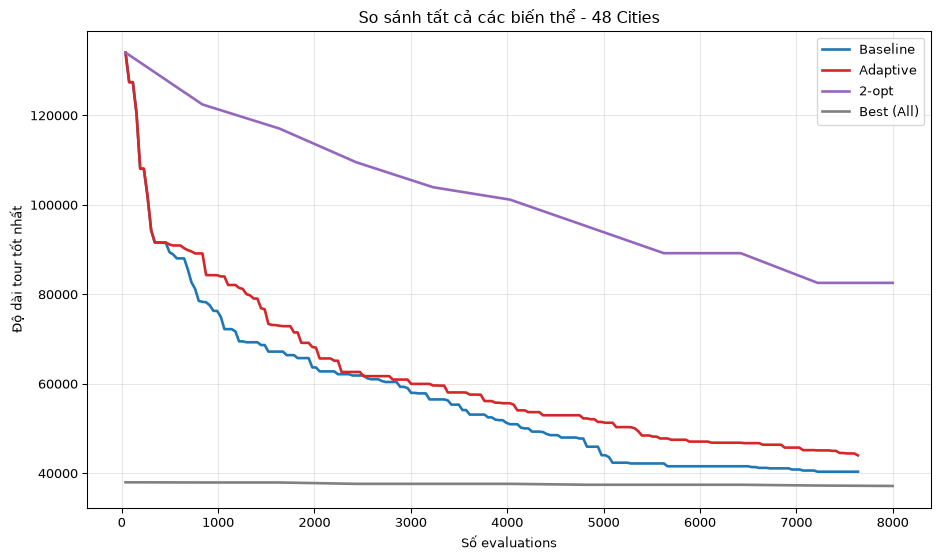

In [8]:
# Best configuration: Tất cả các cải tiến
config_best = replace(
    BASE,
    initialization_method='nearest_neighbor',
    adaptive_mutation=True,
    local_search_enabled=True, local_search_max_moves=50
)
runs_best = [checked_solve(problem_48, replace(config_best, seed=s)) for s in SEEDS]
stats_best = summarize(runs_best)

# So sánh tất cả
show_table(
    ['Biến thể', 'Tốt nhất', 'Trung bình', 'Trung vị', 'Kém nhất', 'Độ lệch chuẩn', 'Thời gian (s)'],
    [
        ['Baseline', f"{stats_fixed['best']:.2f}", f"{stats_fixed['mean']:.2f}", 
         f"{stats_fixed['median']:.2f}", 
             f"{stats_fixed['worst']:.2f}", 
         f"{stats_fixed['std']:.2f}", f"{stats_fixed['seconds']:.4f}"],
        ['+ Adaptive', f"{stats_adaptive['best']:.2f}", f"{stats_adaptive['mean']:.2f}", 
         f"{stats_adaptive['median']:.2f}", 
             f"{stats_adaptive['worst']:.2f}", 
         f"{stats_adaptive['std']:.2f}", f"{stats_adaptive['seconds']:.4f}"],
        ['+ 2-opt', f"{stats_2opt['best']:.2f}", f"{stats_2opt['mean']:.2f}", 
         f"{stats_2opt['median']:.2f}", 
             f"{stats_2opt['worst']:.2f}", 
         f"{stats_2opt['std']:.2f}", f"{stats_2opt['seconds']:.4f}"],
        ['Best (All)', f"{stats_best['best']:.2f}", f"{stats_best['mean']:.2f}", 
         f"{stats_best['median']:.2f}", 
             f"{stats_best['worst']:.2f}", 
         f"{stats_best['std']:.2f}", f"{stats_best['seconds']:.4f}"]
    ]
)

total_improvement = ((stats_fixed['mean'] - stats_best['mean']) / stats_fixed['mean']) * 100
print(f"\nBest (All) thay đổi mean distance: {total_improvement:.2f}% so với baseline")

# Vẽ so sánh tất cả
compare_convergence(
    {
        'Baseline': runs_fixed,
        'Adaptive': runs_adaptive,
        '2-opt': runs_2opt,
        'Best (All)': runs_best
    },
    'So sánh tất cả các biến thể',
    '48 Cities'
)


### 8.5. Nhận xét

Cấu hình Best (All) trên dataset 48 thành phố có mean 37.443,80 so với 43.279,00 của baseline trong năm seed. Kết quả này mô tả riêng cấu hình kết hợp đang thử; không chứng minh các cải tiến có tác động cộng hưởng, và không xóa được kết quả xấu của 2-opt khi chạy riêng.


---

## 9. Kết luận

### 9.1. Kết quả quan sát trong batch hiện tại
- NN initialization có mean thấp hơn baseline trong thí nghiệm riêng trên dataset 26 thành phố.
- Adaptive mutation có mean thấp hơn baseline 1,32% trong thí nghiệm 48 thành phố, nhưng best observed không tốt hơn.
- 2-opt cho mean distance cao hơn baseline trong batch đang lưu; không khuyến nghị dựa trên giả định rằng local search chắc chắn cải thiện kết quả.
- Best (All) có mean thấp hơn baseline trong năm seed trên dataset 48 thành phố; cần thêm seed và kiểm tra từng thành phần trước khi khái quát.

### 9.2. Giới hạn
Các thí nghiệm dùng năm seed và cấu hình/budget riêng theo từng tiểu mục. Không xếp hạng tuyệt đối các cải tiến khác dataset hoặc khẳng định optimum toàn cục từ best observed.
